# Comparing the Python Model with SEBE
Comparing the yearly sunlight from our simplified Python model with the results from SEBE, for rooftops in Sandy Bay and Howrah.

**Inputs**
- Yearly sunlight from the Python model for each test area (from notebook 02)
- Yearly sunlight from SEBE for each test area (run in QGIS)
- Building footprints for each test area (from notebook 01)
- Slope, aspect and roughness for each test area (from notebook 02)

## Setup

Importing the libraries and setting the folders used through the notebook.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import rasterio
from rasterio.features import rasterize
from rasterio.plot import plotting_extent
from rasterstats import zonal_stats

# Folders for the input data and the files we create
inpath = Path("/Users/lailamclennan/Documents/CODING/AT3/Inputs")
outpath = Path("/Users/lailamclennan/Documents/CODING/AT3/Outputs")

## 1. Read in the Python model results

Reading in the yearly sunlight rasters that were saved at the end of notebook 02. This means the model does not need to be run again here.

In [2]:
# For each area open the file, read the yearly sunlight into an
# array, keep the grid details for later, and close the file

# West (Sandy Bay)
west_file = rasterio.open(outpath / "West_yearly_sunlight.tif")
west_model = west_file.read(1)
west_profile = west_file.profile
west_file.close()

# East (Howrah)
east_file = rasterio.open(outpath / "East_yearly_sunlight.tif")
east_model = east_file.read(1)
east_profile = east_file.profile
east_file.close()

# Map coordinates of each raster's edges, so every plot can show
# eastings and northings
west_extent = plotting_extent(west_model, west_profile["transform"])
east_extent = plotting_extent(east_model, east_profile["transform"])

## 2. Read in the SEBE results

Reading in the yearly sunlight raster that SEBE produced for each test area, and checking it sits on the same grid as our model results.

## 3. Building footprints

Reading in the building footprints for each test area and turning them into a roof mask on the same grid as the rasters. The mask is True for pixels inside a building and False everywhere else, so the comparison can be limited to roofs.

In [3]:
# Read in the building footprints for each test area
west_buildings = gpd.read_file(outpath / "Buildings_West.shp")   # Sandy Bay
east_buildings = gpd.read_file(outpath / "Buildings_East.shp")   # Howrah

# Check the coordinate systems and how many buildings there are
print("West buildings:", len(west_buildings), " CRS:", west_buildings.crs)
print("East buildings:", len(east_buildings), " CRS:", east_buildings.crs)

West buildings: 581  CRS: EPSG:7855
East buildings: 279  CRS: EPSG:7855


In [4]:
# Some footprints in the LIST data are 2 m by 2 m placeholder squares
# and not real building outlines. We remove anything smaller than
# 5 m², which takes out the placeholders (4 m²) and keeps real buildings
west_buildings = west_buildings[west_buildings.geometry.area > 5]
east_buildings = east_buildings[east_buildings.geometry.area > 5]

print("West buildings after removing placeholders:", len(west_buildings))
print("East buildings after removing placeholders:", len(east_buildings))

West buildings after removing placeholders: 484
East buildings after removing placeholders: 257


In [5]:
# Turn the building polygons into a grid that matches the rasters.
# Pixels inside a building get 1 and everything else gets 0

# West (Sandy Bay)
west_grid = rasterize(
    west_buildings.geometry,
    out_shape=west_model.shape,
    transform=west_profile["transform"],
)

# East (Howrah)
east_grid = rasterize(
    east_buildings.geometry,
    out_shape=east_model.shape,
    transform=east_profile["transform"],
)

# Turn the 1s and 0s into True and False, so True means roof
west_roofs = west_grid == 1
east_roofs = east_grid == 1

# Check how much of each area is roof
print("West area covered by roofs:", round(west_roofs.mean() * 100), "%")
print("East area covered by roofs:", round(east_roofs.mean() * 100), "%")

West area covered by roofs: 21 %
East area covered by roofs: 13 %


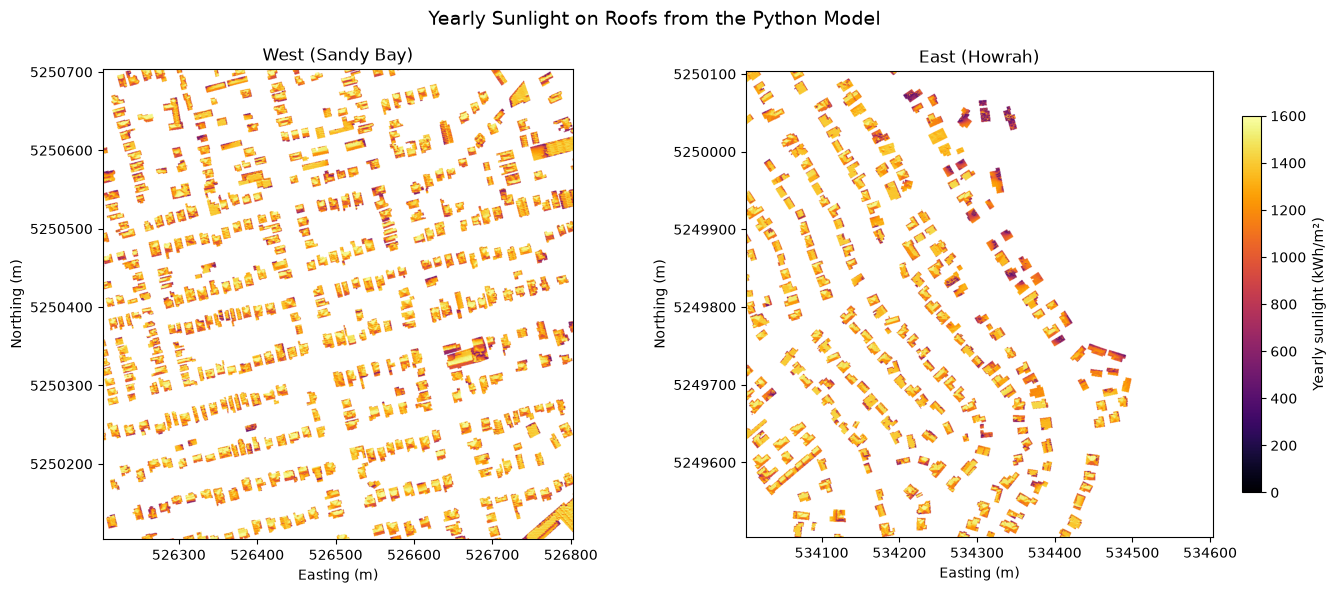

In [18]:
# Plot the model results for roofs only, to check the footprints line up with the buildings
# np.where keeps the value where there is a roof and leaves the rest blank
west_roofs_only = np.where(west_roofs, west_model, np.nan)
east_roofs_only = np.where(east_roofs, east_model, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# West (Sandy Bay)
west_plot = axes[0].imshow(west_roofs_only, cmap="inferno", vmin=0, vmax=1600, extent=west_extent)
axes[0].set_title("West (Sandy Bay)")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")
axes[0].ticklabel_format(style="plain", useOffset=False)  # show full coordinates instead of scientific notation

# East (Howrah)
east_plot = axes[1].imshow(east_roofs_only, cmap="inferno", vmin=0, vmax=1600, extent=east_extent)
axes[1].set_title("East (Howrah)")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")
axes[1].ticklabel_format(style="plain", useOffset=False)

# One colourbar covers both maps because they share the same scale
fig.colorbar(east_plot, ax=axes[1], label="Yearly sunlight (kWh/m²)", shrink=0.8)

fig.suptitle("Yearly Sunlight on Roofs from the Python Model", fontsize=14)
plt.tight_layout()

# Save the figure so we can use it on the website
fig.savefig("Images/yearly_sunlight_roofs.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# For each building, find the average yearly sunlight of the pixels
# inside it and how many pixels that was

# West (Sandy Bay)
west_stats = zonal_stats(
    west_buildings,
    outpath / "West_yearly_sunlight.tif",
    stats=["mean", "count"],
    nodata=-999,
)

# East (Howrah)
east_stats = zonal_stats(
    east_buildings,
    outpath / "East_yearly_sunlight.tif",
    stats=["mean", "count"],
    nodata=-999,
)

# zonal_stats gives one result per building, in the same order as the
# buildings. We put the results in a table and copy each column across
west_table = pd.DataFrame(west_stats)
west_buildings["model_mean"] = west_table["mean"].values
west_buildings["pixels"] = west_table["count"].values

east_table = pd.DataFrame(east_stats)
east_buildings["model_mean"] = east_table["mean"].values
east_buildings["pixels"] = east_table["count"].values

# Look at the first few rows to check it worked
west_buildings[["BUILD_ID", "model_mean", "pixels"]].head()

,BUILD_ID,model_mean,pixels
0,180989,1127.250110,71
1,180990,1291.278892,623
2,182508,1328.553522,543
3,180988,1281.380396,973
4,180945,1451.249187,346


## 4. Results per building

Working out the average yearly sunlight on each roof from our model. This gives one value per building, which can be used to rank the roofs and later to compare with SEBE.

In [7]:
# For each building, find the average yearly sunlight of the pixels
# inside it and how many pixels that was

# West (Sandy Bay)
west_stats = zonal_stats(
    west_buildings,
    outpath / "West_yearly_sunlight.tif",
    stats=["mean", "count"],
    nodata=-999,
)

# East (Howrah)
east_stats = zonal_stats(
    east_buildings,
    outpath / "East_yearly_sunlight.tif",
    stats=["mean", "count"],
    nodata=-999,
)

# zonal_stats gives one result per building, in the same order as the
# buildings. We put the results in a table and copy each column across
west_table = pd.DataFrame(west_stats)
west_buildings["model_mean"] = west_table["mean"].values
west_buildings["pixels"] = west_table["count"].values

east_table = pd.DataFrame(east_stats)
east_buildings["model_mean"] = east_table["mean"].values
east_buildings["pixels"] = east_table["count"].values

# Look at the first few rows to check it worked
west_buildings[["BUILD_ID", "model_mean", "pixels"]].head()

,BUILD_ID,model_mean,pixels
0,180989,1127.250110,71
1,180990,1291.278892,623
2,182508,1328.553522,543
3,180988,1281.380396,973
4,180945,1451.249187,346


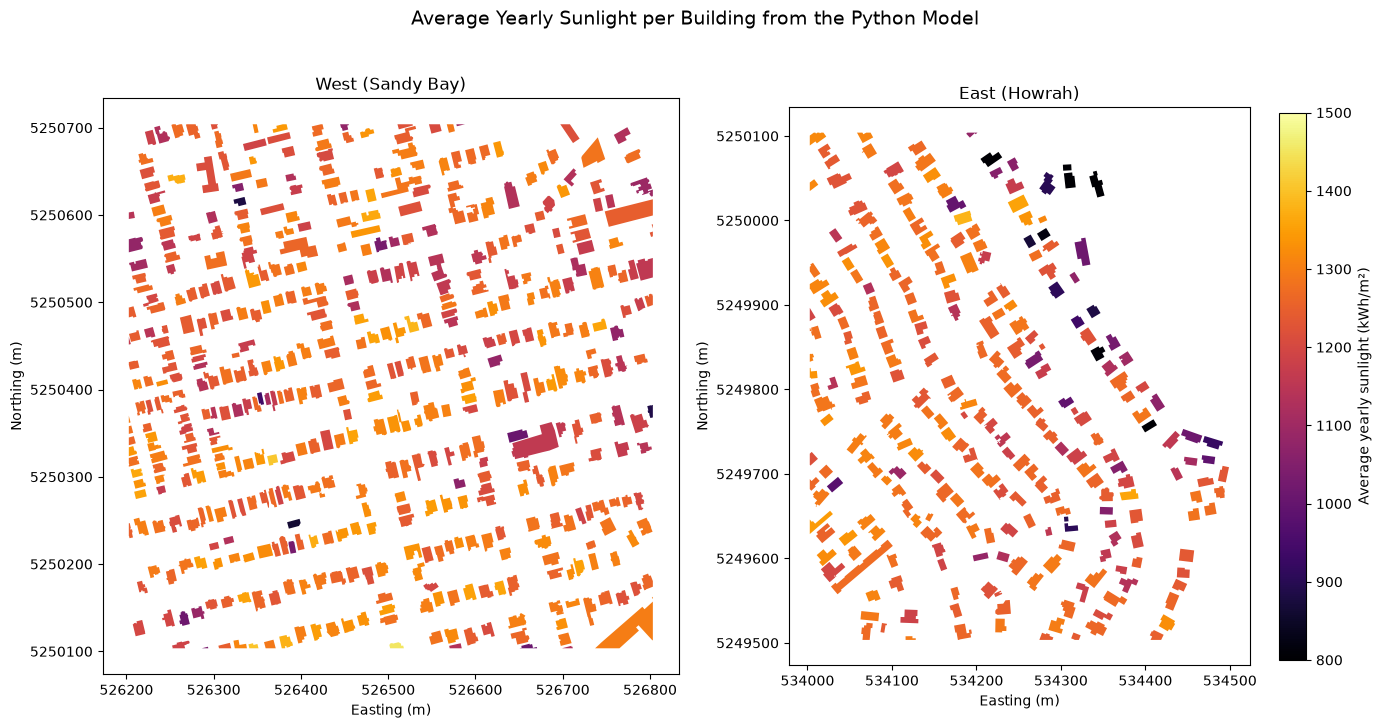

In [11]:
# Map each building coloured by its average yearly sunlight
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))

# West (Sandy Bay)
west_buildings.plot(
    column="model_mean", cmap="inferno", vmin=800, vmax=1500, ax=axes[0]
)
axes[0].set_title("West (Sandy Bay)")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")
# Show full coordinates instead of scientific notation
axes[0].ticklabel_format(style="plain", useOffset=False)

# East (Howrah)
# legend=True adds the colourbar, which covers both maps because they
# share the same scale
colourbar_settings = {
    "label": "Average yearly sunlight (kWh/m²)",
    "shrink": 0.8,
}
east_buildings.plot(
    column="model_mean",
    cmap="inferno",
    vmin=800,
    vmax=1500,
    ax=axes[1],
    legend=True,
    legend_kwds=colourbar_settings,
)
axes[1].set_title("East (Howrah)")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")
axes[1].ticklabel_format(style="plain", useOffset=False)

fig.suptitle(
    "Average Yearly Sunlight per Building from the Python Model",
    fontsize=14,
)
plt.tight_layout()

# Save the figure so we can use it on the website
fig.savefig("Images/sunlight_per_building.png", dpi=200, bbox_inches="tight")
plt.show()